In [82]:
path = '/kaggle/input/datasets/almutalem/rehab24-6-2d-30fps-repetition-extracted/processed_repetitions/2d_joints/Ex1'

In [83]:
import re
import os

FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

In [84]:
# person-disjoint deterministic split
import numpy as np
from sklearn.model_selection import train_test_split
from collections import defaultdict

def subject_split(records, test_size=0.8, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based"""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)
    strata_arr  = np.array(strata)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, stratify=strata_arr, shuffle=True)
    except ValueError:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [85]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=9 persons, test=3 persons | train reps P=56, test reps P=24


In [86]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
g = lambda s, name: s[:, JN[name], :]

In [87]:
# bone sets (upper body = feature mask; full body = ghost drawing)
UPPER_BONES = [(0, 1), (1, 2), (2, 3), (3, 4),
               (6, 7), (7, 8), (8, 9),
               (11, 12), (12, 13), (13, 14),
               (0, 6), (0, 11), (1, 6), (1, 11)]

LEG_BONES = [(0, 16), (0, 21),
             (16, 17), (17, 18), (18, 19), (19, 20),
             (21, 22), (22, 23), (23, 24), (24, 25)]

HEAD_TIP  = [(4, 5), (9, 10), (14, 15)]
FULL_BONES = UPPER_BONES + LEG_BONES + HEAD_TIP

In [88]:
from dataclasses import dataclass

@dataclass
class Ex1Config:
    n_frames: int = 90
    sgf_win: int = 11
    sgf_poly: int = 2

    use_angles: bool = True
    use_bone_vectors: bool = True
    use_arm_positions: bool = True
    use_angular_velocity: bool = True
    use_angular_accel: bool = False
    use_joint_speed: bool = False

    use_mirror_canonicalization: bool = True
    torso_eps: float = 1e-6

    angle_defs: tuple = (
        ("Neck", "LeftShoulder", "LeftArm"),
        ("Neck", "RightShoulder", "RightArm"),
        ("LeftShoulder", "LeftArm", "LeftForeArm"),
        ("RightShoulder", "RightArm", "RightForeArm"),
        ("LeftArm", "LeftForeArm", "LeftHand"),
        ("RightArm", "RightForeArm", "RightHand"),
        ("Hips", "Spine1", "Neck"),
    )
    arm_position_joints: tuple = ("LeftArm", "LeftForeArm", "LeftHand", "RightArm", "RightForeArm", "RightHand")

CFG = Ex1Config()

### normalizers (canonical -> spatial -> smooth -> resample)

In [89]:
def mirror_x(seq: np.ndarray) -> np.ndarray:
    """Mirror about the pelvis vertical axis. seq: (T,26,2)."""
    pelvis_x = seq[:, JN["Hips"], 0:1]
    out = seq.copy()
    out[:, :, 0] = 2.0 * pelvis_x - out[:, :, 0]
    return out

def canonicalize(seq, is_mirror_rep, cfg: Ex1Config = CFG):
    if cfg.use_mirror_canonicalization and is_mirror_rep:
        return mirror_x(seq)
    return seq.copy()

In [90]:
def spatial_normalize(seq, cfg: Ex1Config = CFG):
    out = seq.copy() - seq[:, JN["Hips"], :][:, None, :]
    a = seq[:, JN["Hips"], :]
    b = seq[:, JN["Spine"], :]
    tl = np.linalg.norm(b - a, axis=-1)
    tl = np.maximum(tl, cfg.torso_eps)
    return out / tl[:, None, None]

In [91]:
from scipy.signal import savgol_filter

def smooth(seq, cfg: Ex1Config = CFG):
    T = seq.shape[0]
    win = min(cfg.sgf_win if cfg.sgf_win % 2 == 1 else cfg.sgf_win + 1, (T // 2) * 2 + 1)
    if win < 5:
        return seq
    return np.stack([savgol_filter(seq[:, j, :], win, cfg.sgf_poly, axis=0)
                     for j in range(seq.shape[1])], axis=1)

In [92]:
def resample(seq, n=None):
    n = CFG.n_frames if n is None else n
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs = np.arange(T)
    xd = np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

### feature extractors

In [93]:
def angle_abc(a, b, c):
    ab, bc = a - b, c - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1, 1)))

def angle_channels(seq, cfg: Ex1Config = CFG):
    feats, names = [], []
    for (p, v, d) in cfg.angle_defs:
        feats.append(angle_abc(g(seq, p), g(seq, v), g(seq, d)))
        names.append(f"ang_{v}")
    sh = g(seq, "RightShoulder") - g(seq, "LeftShoulder")
    feats.append(np.degrees(np.arctan2(sh[:, 1], sh[:, 0])))
    names.append("ang_shoulder_tilt")
    return np.stack(feats, axis=1), names

def bone_channels(seq, cfg: Ex1Config = CFG):
    feats, names = [], []
    for (s, e) in UPPER_BONES:
        v = seq[:, e, :] - seq[:, s, :]
        feats.append(v[:, 0]); names.append(f"bone_{s}_{e}_x")
        feats.append(v[:, 1]); names.append(f"bone_{s}_{e}_y")
    return np.stack(feats, axis=1), names

def arm_position_channels(seq, cfg: Ex1Config = CFG):
    feats, names = [], []
    for name in cfg.arm_position_joints:
        p = g(seq, name)
        feats.append(p[:, 0]); names.append(f"pos_{name}_x")
        feats.append(p[:, 1]); names.append(f"pos_{name}_y")
    return np.stack(feats, axis=1), names

def kinematic_channels(angles, seq, cfg: Ex1Config = CFG):
    feats, names = [], []
    if cfg.use_angular_velocity:
        feats.append(np.gradient(angles, axis=0))
        names += [f"dang_{i}" for i in range(angles.shape[1])]
    if cfg.use_angular_accel:
        feats.append(np.gradient(angles, axis=0, edge_order=2)
                     if angles.shape[0] > 2 else np.zeros_like(angles))
        names += [f"d2ang_{i}" for i in range(angles.shape[1])]
    if cfg.use_joint_speed:
        v = np.gradient(seq, axis=0)
        speeds = np.linalg.norm(v, axis=-1)
        sel = [JN[n] for n in cfg.arm_position_joints]
        feats.append(speeds[:, sel])
        names += [f"speed_{cfg.arm_position_joints[i]}" for i in range(len(sel))]
    if not feats:
        return np.zeros((angles.shape[0], 0)), []
    return np.concatenate(feats, axis=1), names

### per-rep pipeline

In [94]:
def build_rep(coord, is_mirror_rep=False, cfg: Ex1Config = CFG, return_template=True):
    x = np.asarray(coord, dtype=np.float64)
    x = canonicalize(x, is_mirror_rep, cfg)
    x = spatial_normalize(x, cfg)
    x_s = smooth(x, cfg)
    x_r = resample(x_s, cfg.n_frames)

    blocks, blk_names = [], []
    if cfg.use_angles:
        a, n = angle_channels(x_r, cfg)
        blocks.append(a); blk_names += n
        kin, kn = kinematic_channels(a, x_r, cfg)
        blocks.append(kin); blk_names += kn
    if cfg.use_bone_vectors:
        b, n = bone_channels(x_r, cfg)
        blocks.append(b); blk_names += n
    if cfg.use_arm_positions:
        p, n = arm_position_channels(x_r, cfg)
        blocks.append(p); blk_names += n
    if not blk_names:
        raise ValueError("no feature channels enabled in Ex1Config")

    X = np.concatenate(blocks, axis=1)
    if not np.isfinite(X).all():
        raise ValueError("non-finite features produced (bad rep?)")

    out = {"X": X.astype(np.float32), "names": blk_names}
    if return_template:
        out["template"] = resample(x, cfg.n_frames).astype(np.float32)
    return out

In [95]:
# standardization (fitted on TRAIN persons ONLY)
class FeatureScaler:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        std[std < 1e-8] = 1.0
        self.std_ = std
        return self

    def transform(self, X):
        return ((np.asarray(X, dtype=np.float64) - self.mean_) / self.std_).astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [96]:
# global setup
import copy
import numpy as np
import torch
import torch.nn as nn
import optuna
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve, confusion_matrix)

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
SEED    = 42
N_TRIALS = 40
N_MASKS  = 8
SAVE_PATH = "/kaggle/working"

torch.backends.cudnn.deterministic = True

def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

In [97]:
# feature cache (built ONCE, not inside the Optuna loop)
def build_feature_cache(records, cfg=CFG):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr, r.get("is_mirror_rep", False), cfg)
        rec = dict(r)
        rec["X2d"]      = b["X"]
        rec["template"] = b["template"]
        out.append(rec)
    return out

feat_train = build_feature_cache(train)
feat_test  = build_feature_cache(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps "
      f"| per-rep shape={feat_train[0]['X2d'].shape}")

cached features: train=100 reps, test=49 reps | per-rep shape=(90, 56)


### sequence standardization + spec base class

In [98]:
def std_rows(rows, scaler):
    """Standardize each cached rep (90,56) with the train-fitted scaler -> (N,90,56)."""
    return np.stack([scaler.transform(r["X2d"]) for r in rows]).astype(np.float32)

class ArchSpec:
    """Per-architecture contract. Each arch = one subclass, nothing else to touch."""
    name = "arch"
    def suggest(self, trial): raise NotImplementedError   # Optuna search space
    def train(self, X, p, Xval, seed): raise NotImplementedError   # X = packed
    def score(self, model, X, p): raise NotImplementedError       # (N,) higher=more flawed
    def pack(self, std_list): raise NotImplementedError           # (N,90,56) -> model input
    def embed(self, model, std_list): raise NotImplementedError   # (N,latent) for bank

### metrics (positive class = label 1 = PERFECT) + confusion + ROC

In [99]:
def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    tp=int(np.sum((y_true==1)&(y_pred==1)))
    tn=int(np.sum((y_true==0)&(y_pred==0)))
    fp=int(np.sum((y_true==0)&(y_pred==1)))
    fn=int(np.sum((y_true==1)&(y_pred==0)))
    prec=tp/max(tp+fp,1); rec=tp/max(tp+fn,1)
    spec=tn/max(tn+fp,1); acc=(tp+tn)/max(tp+tn+fp+fn,1)
    f1=2*prec*rec/max(prec+rec,1e-6)
    fb=(1+beta**2)*prec*rec/max(beta**2*prec+rec,1e-6)
    mcc=(float(matthews_corrcoef(y_true,y_pred))
         if len(np.unique(y_true))>=2 else 0.0)
    auroc=(float(roc_auc_score(y_true,y_proba))
           if len(np.unique(y_true))>=2 else 0.0)
    return {'accuracy':acc,'balanced_acc':(rec+spec)/2.0,
            'precision':prec,'recall':rec,'sensitivity':rec,
            'specificity':spec,'f1':f1,f'f{int(beta)}':fb,
            'mcc':mcc,'auroc':auroc,
            'tp':tp,'tn':tn,'fp':fp,'fn':fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm=confusion_matrix(y_true,y_pred,labels=[1,0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print(f"                  Predicted PASS  Predicted FAIL")
    if cm.shape==(2,2):
        tn,fp,fn,tp=cm[0,0],cm[0,1],cm[1,0],cm[1,1]
        print(f"  True PERFECT:  {tp:4d} ({tp/max(tp+fn,1)*100:5.1f}%)    "
              f"{fn:4d} ({fn/max(tp+fn,1)*100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp/max(tn+fp,1)*100:5.1f}%)    "
              f"{tn:4d} ({tn/max(tn+fp,1)*100:5.1f}%)")
    else: print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true))<2: return
    fpr,tpr,_=roc_curve(y_true,y_proba)
    auroc=roc_auc_score(y_true,y_proba)
    fig,ax=plt.subplots(figsize=(5,4))
    ax.plot(fpr,tpr,color='steelblue',lw=2.5, label=f'ROC (AUROC={auroc:.3f})')
    ax.plot([0,1],[0,1],'k--',lw=1,label='Random')
    ax.set_xlabel('FPR (1-Specificity)',fontsize=9)
    ax.set_ylabel('TPR (Sensitivity)',fontsize=9)
    ax.set_title(f'{exercise_id} — ROC Curve',fontsize=10)
    ax.legend(fontsize=8); ax.grid(True,ls=':',alpha=0.4)
    fpath=os.path.join(save_path,f'{exercise_id}_roc_v11.png')
    plt.savefig(fpath,dpi=100,bbox_inches='tight'); plt.close()
    display(IPImage(fpath))
    return fpath

In [100]:
# deterministic person-level splits
def inner_person_split(feats, val_frac=0.25, seed=SEED):
    persons = sorted({f["person_id"] for f in feats})
    parr = np.array(persons)
    tr, va = train_test_split(parr, test_size=val_frac, random_state=seed, shuffle=True)
    return set(tr.tolist()), set(va.tolist())

def make_person_folds(feats, n_folds=2, seed=SEED):
    """Deterministic person-disjoint fold assignment (sorted before seeding)."""
    persons = sorted({f["person_id"] for f in feats})
    perm = np.random.default_rng(seed).permutation(len(persons))
    return [set(np.array(persons)[chunk].tolist())
            for chunk in np.array_split(perm, n_folds)]

## ARCHITECTURE 1: dynamic masked MLP autoencoder

In [101]:
class MaskedAE(nn.Module):
    def __init__(self, in_dim, p):
        super().__init__()
        dims = np.geomspace(p["width"], p["latent"], p["n_layers"])
        dims = np.maximum(np.round(dims).astype(int), 8)
        dims[0], dims[-1] = p["width"], p["latent"]
        act = {"relu": nn.ReLU, "gelu": nn.GELU, "tanh": nn.Tanh}[p["act"]]

        enc, d = [], in_dim
        for h in dims:
            enc += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]
            d = h
        dec, d = [], p["latent"]
        for h in reversed(dims[:-1]):
            dec += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]
            d = h
        dec += [nn.Linear(d, in_dim)]
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))

def train_ae(Xc, p, Xval_c=None, seed=SEED, patience=15):
    set_seed(seed)
    model = MaskedAE(Xc.shape[1], p).to(DEVICE)
    xt = torch.tensor(Xc, device=DEVICE)
    xv = torch.tensor(Xval_c, device=DEVICE) if Xval_c is not None and len(Xval_c) else None
    opt   = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    keep  = 1.0 - p["mask_ratio"]
    vis_w = p["vis_weight"]
    best, best_state, bad = np.inf, None, 0

    for ep in range(p["epochs"]):
        model.train()
        perm = torch.randperm(xt.size(0), device=DEVICE)
        for i in range(0, xt.size(0), p["batch"]):
            xb = xt[perm[i:i + p["batch"]]]
            mkeep = torch.bernoulli(torch.full_like(xb, keep))
            pred  = model(xb * mkeep)
            e2    = (pred - xb) ** 2
            msk   = 1.0 - mkeep
            loss  = (e2 * msk).sum() / msk.sum().clamp(min=1) \
                  + vis_w * (e2 * mkeep).sum() / mkeep.sum().clamp(min=1)
            opt.zero_grad(); loss.backward(); opt.step()

        val = loss.item()
        if xv is not None:
            model.eval()
            with torch.no_grad():
                val = float(((model(xv) - xv) ** 2).mean())
        sched.step(val)
        if val < best - 1e-6:
            best, best_state, bad = val, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, best

def ae_scores(model, X, mask_ratio, seed=SEED + 1, n_masks=N_MASKS):
    """Higher = more flawed. MC-masked reconstruction error (device-safe)."""
    model.eval()
    xt   = torch.tensor(X, device=DEVICE)
    g    = torch.Generator().manual_seed(seed)
    keep = 1.0 - mask_ratio
    errs = torch.zeros(xt.size(0), device=DEVICE)
    with torch.no_grad():
        for _ in range(n_masks):
            mkeep = torch.bernoulli(torch.full(xt.shape, keep), generator=g).to(DEVICE)
            pred  = model(xt * mkeep)
            e2    = (pred - xt) ** 2
            msk   = 1.0 - mkeep
            errs  = errs + (e2 * msk).sum(1) / msk.sum(1).clamp(min=1)
    return (errs / n_masks).cpu().numpy()

class MLPAESpec(ArchSpec):
    name = "Ex1-MLP-AE"
    def suggest(self, trial):
        return dict(
            n_layers=trial.suggest_int("n_layers", 2, 5),
            width=trial.suggest_categorical("width", [512, 1024, 2048, 4096]),
            latent=trial.suggest_categorical("latent", [16, 32, 64, 128]),
            act=trial.suggest_categorical("act", ["relu", "gelu"]),
            dropout=trial.suggest_float("dropout", 0.0, 0.4),
            mask_ratio=trial.suggest_float("mask_ratio", 0.05, 0.5),
            vis_weight=trial.suggest_categorical("vis_weight", [0.0, 0.05, 0.2]),
            lr=trial.suggest_float("lr", 1e-5, 3e-3, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            batch=trial.suggest_categorical("batch", [64, 128, 256]),
            epochs=trial.suggest_categorical("epochs", [80, 160, 240]),
            q=trial.suggest_float("q", 60.0, 99.0),
        )
    def pack(self, std_list):
        return np.stack([s.ravel() for s in std_list]).astype(np.float32)   # (N, F*D)
    def train(self, X, p, Xval, seed):
        return train_ae(X, p, Xval_c=Xval, seed=seed)[0]
    def score(self, model, X, p):
        return ae_scores(model, X, p["mask_ratio"])
    def embed(self, model, std_list):
        X = np.stack([s.ravel() for s in std_list]).astype(np.float32)
        with torch.no_grad():
            return model.encoder(torch.tensor(X, device=DEVICE)).cpu().numpy()

### generic Optuna tuner + finalize + OOF-Platt (work for ANY spec)

In [114]:
def _is_sup(spec): return bool(getattr(spec, "supervised", False))

def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    persons = sorted({r["person_id"] for r in rows})
    rng = np.random.RandomState(SEED)
    idx = rng.permutation(len(persons))
    val_p = set(persons[int(i)] for i in idx[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train persons={len(tr_r)} val persons={len(va_r)}")

    def objective(trial):
        p = spec.search_space(trial)
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in tr_r if r["label"] == 1], 0))
        Xt = spec.pack(std_rows(tr_r, sc)); vt = spec.pack(std_rows(va_r, sc))
        y_tr = np.array([r["label"] for r in tr_r])
        model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
                 else spec.train(Xt, p, None, SEED))
        s_tr = spec.score(model, Xt, p); s_va = spec.score(model, vt, p)
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p["q"]) if _is_sup(spec) \
              else np.percentile(s_tr[  np.ones(len(s_tr), bool)], p["q"])
        mcc = matthews_corrcoef(y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
              sampler=optuna.samplers.TPESampler(seed=SEED),
              pruner=optuna.pruners.MedianPruner())
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study

def finalize_for(spec, study, feats_train, feats_test):
    p = dict(study.best_params)
    Xc_rows = [f for f in feats_train if f["label"] == 1]
    scaler  = FeatureScaler().fit(np.concatenate([r["X2d"] for r in Xc_rows], 0))
    set_seed(SEED)
    Xt = spec.pack(std_rows(feats_train if _is_sup(spec) else Xc_rows, scaler))
    y_tr = np.array([f["label"] for f in feats_train])
    model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
             else spec.train(Xt, p, None, SEED))
    errs_c = spec.score(model, spec.pack(std_rows(Xc_rows, scaler)), p)
    thr    = float(np.percentile(errs_c, p["q"]))
    print(f"provisional score threshold: {thr:.6f}")

    Xt_rows = list(feats_test)
    st = spec.score(model, spec.pack(std_rows(Xt_rows, scaler)), p)
    yt = np.array([r["label"] for r in Xt_rows])
    
    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print(f"  [{spec.name}] scores: correct mean={st[yt==1].mean():.5f} "
          f"flawed mean={st[yt==0].mean() if (yt==0).any() else float('nan'):.5f}")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, (-st if not _is_sup(spec) else st), spec.name)
    return dict(spec=spec, params=p, scaler=scaler, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=Xt_rows, study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    p = dict(study.best_params)
    persons = sorted({f["person_id"] for f in feat_train})
    pl, ys = [], []
    for fold, ps in enumerate([set(persons[0::2]), set(persons[1::2])][:n_folds]):
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        sc = FeatureScaler().fit(np.concatenate(
            [r["X2d"] for r in tr_r if r["label"] == 1], 0))
        Xt = spec.pack(std_rows(tr_r if _is_sup(spec) else
            [f for f in tr_r if f["label"] == 1], sc))
        model = (spec.train(Xt, np.array([r["label"] for r in tr_r]), p, SEED)
                 if _is_sup(spec) else spec.train(Xt, p, None, SEED))
        s = spec.score(model, spec.pack(std_rows(te_r, sc)), p)
        pl += [np.log(np.clip(s, 1e-4, None))]
        ys += [f["label"] for f in te_r]
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)
    ys_f = 1.0 - ys                                  # 1 = FLAWED (model score unit)
    lr2 = LogisticRegression(max_iter=1000).fit(pl.reshape(-1, 1), ys_f.astype(int))
    p_flawed = lr2.predict_proba(pl.reshape(-1, 1))[:, 1]
    auroc = roc_auc_score(ys_f, p_flawed)            # flawed-ranking AUROC (correct sign by construction)
    print(f"  Platt a={lr2.coef_[0][0]:.3f} b={lr2.intercept_[0]:.3f} | "
          f"OOF AUROC(flawed)={auroc:.3f} | P(flawed): correct="
          f"{p_flawed[ys_f==0].mean():.3f} flawed={p_flawed[ys_f==1].mean():.3f}")
    return {"a": float(lr2.coef_[0][0]), "b": float(lr2.intercept_[0])}

def platt_p_perfect(platt, scores):
    z = platt["a"] * np.log(np.clip(scores, 1e-4, None)) + platt["b"]
    return 1.0 / (1.0 + np.exp(-z))

def platt_p_flawed(platt, scores):
    z = platt["a"] * np.log(np.clip(scores, 1e-4, None)) + platt["b"]
    return 1.0 / (1.0 + np.exp(-z))          # P(flawed)

### CorrectionBank + summary (embed_fn provided via spec closure)

In [103]:
JN_R = {v: k for k, v in JN.items()}

class CorrectionBank:
    def __init__(self, records, embed_fn):
        self.records = records
        self.embed_fn = embed_fn
        self.embs = embed_fn(records)
        self.by_person = {}
        for rec, e in zip(records, self.embs):
            self.by_person.setdefault(rec["person_id"], []).append((e, rec))

    def query(self, rec):
        q = self.embed_fn([rec])[0]
        pool = self.by_person.get(rec["person_id"]) or list(zip(self.embs, self.records))
        d = np.array([np.linalg.norm(q - e) for e, _ in pool])
        i = int(np.argmin(d))
        return pool[i][1], float(d[i])

    def correct(self, rec):
        ref, dist = self.query(rec)
        delta = ref["template"] - rec["template"]
        return {"ref": ref, "distance": dist, "delta": delta,
                "per_joint_disp": np.linalg.norm(delta, axis=-1).mean(0)}

def bank_summary(corr, top_k=4):
    """y grows DOWNWARD in the data: delta_y < 0 late in the rep -> 'raise it'."""
    top = np.argsort(-corr["per_joint_disp"])[:top_k]
    disp, delta = corr["per_joint_disp"], corr["delta"]
    F = delta.shape[0]
    imax = int(np.argmax(np.linalg.norm(delta, axis=-1), axis=None) // delta.shape[1])
    print(f"  reference distance (latent space): {corr['distance']:.4f}")
    print(f"  peak mismatch around frame {imax}/{F} "
          f"({'late' if imax > F/2 else 'early' if imax < F/4 else 'mid'} phase)")
    for j in top:
        print(f"   joint {j:>2} ({JN_R[j]:<13}) mean offset={disp[j]:.3f} torso-units")

### ghost overlay (full skeleton, shared window, y-down fixed)

In [104]:
def _draw_skel(ax, P, color, lw=1.2, label=None, ls="-"):
    ax.scatter(P[:, 0], P[:, 1], s=10, c=color, zorder=3, label=label)
    emphasized = set(UPPER_BONES)
    for s, e in FULL_BONES:
        if (s, e) in emphasized:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=lw, ls=ls, zorder=2)
        else:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=0.7, ls=ls, alpha=0.45, zorder=1)

def plot_ghost_overlay(rec, corr, sel=None, top_k=4, save_path=SAVE_PATH, prefix="Ex1"):
    rep, ref = rec["template"], corr["ref"]["template"]
    F = rep.shape[0]
    sel = sel or [0, F // 4, F // 2, 3 * F // 4, F - 1]
    top = np.argsort(-corr["per_joint_disp"])[:top_k]
    
    frames = np.concatenate([rep[sel], ref[sel]], axis=0)
    pad = 0.15
    x0, x1 = frames[:, :, 0].min(), frames[:, :, 0].max()
    y0, y1 = frames[:, :, 1].min(), frames[:, :, 1].max()
    xr, yr = (x1 - x0) or 1.0, (y1 - y0) or 1.0
    xlim, ylim = (x0 - pad * xr, x1 + pad * xr), (y0 - pad * yr, y1 + pad * yr)

    fig, axes = plt.subplots(1, len(sel), figsize=(3.1 * len(sel), 4.2))
    for ax, t in zip(np.atleast_1d(axes), sel):
        _draw_skel(ax, ref[t], "0.45", ls=":", label="ghost (correct ref)" if t == sel[0] else None)
        _draw_skel(ax, rep[t], "steelblue", label="performed rep" if t == sel[0] else None)
        for j in top:
            ax.annotate("", xy=ref[t, j], xytext=rep[t, j],
                        arrowprops=dict(arrowstyle="->", lw=1.4, color="crimson"))
        ax.set_xlim(*xlim)
        ax.set_ylim(ylim[1], ylim[0])     # y grows DOWNWARD in the data
        ax.set_aspect("equal")            # shared honest scale for all panels
        ax.set_title(f"frame {t}", fontsize=9); ax.axis("off")
    axes = np.atleast_1d(axes)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"{prefix} ghost overlay — {rec['person_id']} rep{rec['rep']} "
                 f"| latent dist={corr['distance']:.3f}", fontsize=10)
    fpath = os.path.join(save_path, f"{prefix}_ghost_{rec['person_id']}_rep{rec['rep']}.png")
    plt.savefig(fpath, dpi=110, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

## THE runner: one call per architecture

In [105]:
def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2, show_bank=True, ex_name=None):
    ex  = ex_name or spec.name
    print(f"\n================ {ex} ================")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.best_params)

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)
    p_flawed = platt_p_flawed(platt, best["scores"])
    y_pred_platt = (p_flawed < 0.5).astype(int)      # PASS when P(flawed) < 0.5
    m = compute_all_metrics(best["y"], y_pred_platt, 1.0 - p_flawed)  # proba for PERFECT class
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], y_pred_platt, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")
    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)

    if show_bank:
        model, scaler = best["model"], best["scaler"]
        bank = CorrectionBank([f for f in feat_train if f["label"] == 1],
                              embed_fn=lambda rows: spec.embed(model, std_rows(rows, scaler)))
        i = int(np.argmin(p_pass))
        rec = best["rows"][i]
        print(f"worst test rep: {rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_pass={p_pass[i]:.3f}")
        corr = bank.correct(rec)
        bank_summary(corr)
        plot_ghost_overlay(rec, corr, prefix=ex)
    return best

In [ ]:
mlp_bundle = run_experiment(MLPAESpec(),  feat_train, feat_test)

# Ex1 — MLP-AE: findings
**Setup**
- 40 Optuna trials, objective = mcc + auroc on the 19-rep val slice.
- Best trial 17 (0.902): 4×512 GELU, latent 16, dropout 0.257, mask 0.482,
  lr 1.9e-4, wd 2.7e-3, batch 128, 80 epochs. Provisional threshold 0.543.

**Numbers (49 test reps, 24 perfect / 25 flawed)**
- Score direction is now correct: flawed mean 4.01 > correct mean 2.79
  (the earlier run was inverted 349 vs 83 — that was the device/mask bug, now fixed).
- Ranking above chance but weak: test AUROC 0.63.
- Threshold cuts badly: MCC 0.0076, accuracy 0.51, recall 0.125,
  specificity 0.88, F1 0.20. Confusion TP 3 / FN 21 / TN 22 / FP 3 —
  i.e. 22 of 25 flawed reps are correctly flagged, but 21 of 24 perfect
  reps get flagged too ("fails everything" mode).
- Val ranking (0.839) did not transfer; OOF stayed ≈ 0.5.

**Reasons**
- ~9 train persons is the ceiling: the AE partly grades "which person",
  not "which form". No architecture change fixes that with this data size.
- The provisional percentile threshold sits far too strict on such a weak
  ranking; with AUROC 0.63 no cut can give both good recall and specificity.

## ARCHITECTURE 2: dynamic ANN+CNN+RNN hybrid

In [106]:
class MaskedHybridAE(nn.Module):
    """
    CNN front-end (time-conv) -> GRU -> ANN latent head; MLP decoder -> (F, D).
    All sizes from Optuna params -> dynamic.
    """
    def __init__(self, F, D, p):
        super().__init__()
        act = {"relu": nn.ReLU, "gelu": nn.GELU}[p["act"]]
        k = p["cnn_kernel"]
        front = [nn.Conv1d(D, p["cnn_ch1"], k, padding=k // 2), act()]
        if p["cnn_pool"]:
            front += [nn.MaxPool1d(2)]
        front += [nn.Conv1d(p["cnn_ch1"], p["cnn_ch2"], k, padding=k // 2), act()]
        self.front = nn.Sequential(*front)
        self.gru = nn.GRU(input_size=p["cnn_ch2"], hidden_size=p["gru_hidden"],
                          num_layers=p["gru_layers"], batch_first=True,
                          bidirectional=p["bi"],
                          dropout=0.0 if p["gru_layers"] < 2 else p["dropout"])
        hd = (2 if p["bi"] else 1) * p["gru_hidden"]
        self.to_latent = nn.Sequential(nn.Linear(hd, p["latent"]), act(),
                                       nn.Dropout(p["dropout"]))
        self.dec = nn.Sequential(nn.Linear(p["latent"], p["gru_hidden"]), act(),
                                 nn.Dropout(p["dropout"]),
                                 nn.Linear(p["gru_hidden"], F * D))
        self.F, self.D = F, D

    def encode(self, x):                       # x: (N, F, D)
        h = self.front(x.permute(0, 2, 1))     # (N, C, T)
        o, _ = self.gru(h.permute(0, 2, 1))    # (N, T, H)
        return self.to_latent(o[:, -1, :])     # (N, latent)

    def forward(self, x):
        return self.dec(self.encode(x)).view(-1, self.F, self.D)

def train_seq_ae(X, p, Xval, seed, patience=15):
    """Masked training over sequences (N,F,D); identical rules to train_ae."""
    set_seed(seed)
    model = MaskedHybridAE(X.shape[1], X.shape[2], p).to(DEVICE)
    xt = torch.tensor(X, device=DEVICE)
    xv = torch.tensor(Xval, device=DEVICE) if Xval is not None and len(Xval) else None
    opt   = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    keep, vis_w = 1.0 - p["mask_ratio"], p["vis_weight"]
    best, best_state, bad = np.inf, None, 0
    for ep in range(p["epochs"]):
        model.train()
        perm = torch.randperm(xt.size(0), device=DEVICE)
        for i in range(0, xt.size(0), p["batch"]):
            xb = xt[perm[i:i + p["batch"]]]
            mkeep = torch.bernoulli(torch.full_like(xb, keep))
            pred = model(xb * mkeep)
            e2 = (pred - xb) ** 2
            msk = 1.0 - mkeep
            loss = (e2 * msk).sum() / msk.sum().clamp(min=1) \
                 + vis_w * (e2 * mkeep).sum() / mkeep.sum().clamp(min=1)
            opt.zero_grad(); loss.backward(); opt.step()
        val = loss.item()
        if xv is not None:
            model.eval()
            with torch.no_grad():
                val = float(((model(xv) - xv) ** 2).mean())
        sched.step(val)
        if val < best - 1e-6:
            best, best_state, bad = val, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, best

def ae_scores_seq(model, X, mask_ratio, seed=SEED + 1, n_masks=N_MASKS):
    model.eval()
    xt   = torch.tensor(X, device=DEVICE)
    g    = torch.Generator().manual_seed(seed)
    keep = 1.0 - mask_ratio
    errs = torch.zeros(xt.size(0), device=DEVICE)
    with torch.no_grad():
        for _ in range(n_masks):
            mkeep = torch.bernoulli(torch.full(xt.shape, keep), generator=g).to(DEVICE)
            e2 = (model(xt * mkeep) - xt) ** 2
            msk = 1.0 - mkeep
            errs = errs + (e2 * msk).sum(dim=(1, 2)) / msk.sum(dim=(1, 2)).clamp(min=1)
    return (errs / n_masks).cpu().numpy()

class HybridSpec(ArchSpec):
    name = "Ex1-ANN-CNN-RNN"
    def suggest(self, trial):
        return dict(
            cnn_ch1=trial.suggest_categorical("cnn_ch1", [32, 64, 128]),
            cnn_ch2=trial.suggest_categorical("cnn_ch2", [32, 64, 128]),
            cnn_kernel=trial.suggest_categorical("cnn_kernel", [3, 5, 7]),
            cnn_pool=trial.suggest_categorical("cnn_pool", [False, True]),
            gru_hidden=trial.suggest_categorical("gru_hidden", [64, 128, 256]),
            gru_layers=trial.suggest_int("gru_layers", 1, 3),
            bi=trial.suggest_categorical("bi", [False, True]),
            latent=trial.suggest_categorical("latent", [16, 32, 64, 128]),
            act=trial.suggest_categorical("act", ["relu", "gelu"]),
            dropout=trial.suggest_float("dropout", 0.0, 0.4),
            mask_ratio=trial.suggest_float("mask_ratio", 0.05, 0.5),
            vis_weight=trial.suggest_categorical("vis_weight", [0.0, 0.05, 0.2]),
            lr=trial.suggest_float("lr", 1e-5, 3e-3, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            batch=trial.suggest_categorical("batch", [16, 32, 64]),
            epochs=trial.suggest_categorical("epochs", [80, 160, 240]),
            q=trial.suggest_float("q", 60.0, 99.0),
        )
    def pack(self, std_list):
        return np.stack(std_list).astype(np.float32)            # keep (N, F, D)
    def train(self, X, p, Xval, seed):
        return train_seq_ae(X, p, Xval, seed)[0]
    def score(self, model, X, p):
        return ae_scores_seq(model, X, p["mask_ratio"])
    def embed(self, model, std_list):
        X = np.stack(std_list).astype(np.float32)
        with torch.no_grad():
            return model.encode(torch.tensor(X, device=DEVICE)).cpu().numpy()

In [ ]:
hyb_bundle = run_experiment(HybridSpec(), feat_train, feat_test)

# Ex1 — ANN+CNN+RNN (hybrid): findings
**Setup**
- 40 Optuna trials, objective = mcc + auroc on the ~19-rep val slice.
- Best trial 9 (0.898): Conv1d 32→32 (k=5, pool) + BiGRU 256×1 + latent 32,
  GELU, dropout 0.011, mask 0.314, lr 3.9e-4, wd 6.8e-5, batch 32, 80 epochs.
- Provisional threshold 0.2517 (percentile of train-correct errors).

**Numbers (49 test reps: 25 perfect / 24 flawed)**
- Raw score direction correct: flawed mean 3.44 > correct mean 2.08.
-_raw ranking on test: AUROC 0.743 (MLP-AE: 0.63) — best so far.
- Provisional cut useless in the opposite direction from MLP: 0.2517 sits far
  below the entire test score range (2–3.4) because it was computed on
  *train-correct* errors (~0.25 scale) while unseen persons score 8–10× higher
  → everything predicted PASS, MCC 0.0.
- OOF-Platt (the honest check): **OOF AUROC 0.371 — below chance, inverted**;
  Platt slope a = −0.574 (negative = inversion); P(perfect) barely separates
  (correct 0.583 vs flawed 0.531).
- Platt-thresholded test: MCC 0.371, recall 0.833, specificity 0.52, F1 0.71,
  confusion TP 20 / FN 4 / TN 13 / FP 12.

**Reading**
- The test report looks like our best result ever, but it cannot be trusted:
  OOF AUROC 0.371 + negative Platt slope = the model ranks *unseen persons
  backwards*. The test cut landing well on 2 persons is luck of the
  person-gap, not signal (v22 failure-signature rule → verdict UNCERTAIN).
- Signature is the same memorization ceiling as MLP-AE, just a different
  random manifestation: MLP's OOF was flat (0.496), the hybrid's is inverted
  (0.371) and its over-trained config (dropout 0.011) memorizes harder.
- The 8–10× score-scale gap between train persons (errs ≈ 0.25) and test
  persons (errs ≈ 2–3.4) is direct evidence the AE measures "which person",
  not "which form".

## DTW RefMatch

In [ ]:
%pip install fastdtw

In [107]:
from fastdtw import fastdtw
from sklearn.ensemble import RandomForestClassifier
from scipy.special import expit as sigmoid

ANG  = slice(0, 8); DANG = slice(8, 16)
BONE = slice(16, 44); POS = slice(44, 56)
BLOCKS = {"ang": ANG, "dang": DANG, "bone": BONE, "pos": POS, "full": slice(0, 56)}

def dtw_run(a, b, radius):
    """fastdtw wrapper: returns (normalized dist, path as (i_user, j_ref) pairs)."""
    d, path = fastdtw(a, b, radius=radius,
                      dist=lambda u, v: np.sqrt(np.mean((np.asarray(u) - np.asarray(v)) ** 2)))
    return float(d) / len(a), np.asarray(path, dtype=int)

In [108]:
class DTWRefMatch:
    """Supervised verifier: DTW-to-perfect-references features -> LR/RF head."""

    # NOTE: BLOCKS slices select FEATURE columns (axis 1), so single reps need
    # x[:, blk] and ref stacks need refs[:, :, blk]. The earlier x[blk] /
    # refs[:, blk] silently sliced FRAMES instead — that was the crash source.

    def __init__(self, p):
        self.p = p
        self.blk, self.dblk = BLOCKS[p["dtw_block"]], BLOCKS[p["dev_block"]]
        self.w, self.n_refs = p["dtw_radius"], p["n_refs"]
        self.head_kind = p["head"]

    def _dev_features(self, x, refs_r, refs_d):
        """x (90,56) one rep; refs (N_refs,90,56). Feature vector (8,)."""
        rr, rd = refs_r[:, :, self.blk], refs_d[:, :, self.dblk]   # (N,90,blk)
        xu = x[:, self.blk]                                        # (90,blk)
        # cheap pre-screen of refs: mean |diff| after uniform phase rescale (no warp)
        pre = np.abs(xu[None] - rr).mean(axis=(1, 2))
        take = min(self.n_refs, len(rr))
        cand = np.argsort(pre)[:take]
        ds, pi = [], []
        for j in cand:
            d, path = dtw_run(xu, rr[j], self.w)
            ds.append(d); pi.append(path)
        k   = int(np.argmin(ds))            # winning candidate (position in cand)
        j_b = int(cand[k])                  # its row in refs (0..N_refs-1)
        i_u, j_r = pi[k][:, 0], pi[k][:, 1]   # path steps: (user frame, ref frame)
        # per-STEP deviation vs the matched ref frame, then folded back
        # onto the user's own 90-frame timeline (path can exceed 90 steps)
        step = np.abs(x[i_u][:, self.dblk] - rd[j_b][j_r]).mean(axis=1)   # (L,)
        cnt  = np.bincount(i_u, minlength=90)
        dev  = np.bincount(i_u, weights=step, minlength=90) / np.maximum(cnt, 1)
        f = [float(ds[k]), float(np.mean(ds)), float(np.percentile(ds, 95)),
             dev.mean(), dev.max(), float(np.percentile(dev, 95)), dev.std(),
             dev[len(dev) // 3 * 2:].mean()]                     # late-phase mean
        return np.asarray(f, dtype=np.float64)

    def fit(self, X, y):
        corr = X[y == 1]
        n = min(max(6, len(corr)), 48)
        rng = np.random.RandomState(self.p.get("seed", 0))
        pick = rng.choice(len(corr), size=n, replace=False) if len(corr) > n else np.arange(len(corr))
        self.refs = corr[pick]
        F = np.stack([self._dev_features(x, self.refs, self.refs) for x in X], 0)
        mu, sd = F[y == 1].mean(0), F[y == 1].std(0) + 1e-9
        self.mu, self.sd = mu, sd
        Z = (F - mu) / sd
        yf = (y == 0).astype(int)                                # flawed = 1
        if self.head_kind == "lr":
            self.head = LogisticRegression(C=self.p["lr_C"], max_iter=2000).fit(Z, yf)
        else:
            self.head = RandomForestClassifier(
                n_estimators=300, max_depth=self.p["rf_depth"],
                min_samples_leaf=self.p["rf_leaf"], random_state=0).fit(Z, yf)
        return self

    def _score(self, x):
        f = self._dev_features(x, self.refs, self.refs)
        z = ((f - self.mu) / self.sd)[None]
        if self.head_kind == "lr":
            return float(sigmoid(self.head.decision_function(z)[0]))
        return float(self.head.predict_proba(z)[0, 1])           # P(flawed)

    def scores(self, X):
        return np.array([self._score(x) for x in X], dtype=np.float64)

In [109]:
class DTWSpec(ArchSpec):
    name       = "Ex1-DTW-RefMatch"
    supervised = True

    def search_space(self, trial):
        return {
            "dtw_block":  trial.suggest_categorical("dtw_block", ["ang", "pos", "bone", "full"]),
            "dev_block":  trial.suggest_categorical("dev_block", ["pos", "ang", "bone", "full"]),
            "dtw_radius": trial.suggest_categorical("dtw_radius", [1, 2, 3, 5]),
            "n_refs":     trial.suggest_categorical("n_refs", [12, 20, 32]),
            "head":       trial.suggest_categorical("head", ["lr", "rf"]),
            "lr_C":       trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            "rf_depth":   trial.suggest_int("rf_depth", 3, 9),
            "rf_leaf":    trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            "q":          trial.suggest_float("q", 50.0, 95.0),
        }

    def pack(self, rows):
        X = np.stack([r["X2d"] for r in rows], 0) if isinstance(rows[0], dict) else np.asarray(rows)
        return np.asarray(X, dtype=np.float32)

    def train(self, X, y, params, seed):
        if y is None:
            raise ValueError("DTWSpec is supervised — needs labels")
        return DTWRefMatch(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, X):     # for CorrectionBank: per-rep mean channel profile
        return np.asarray(X).mean(axis=1)

[I 2026-10-21 12:28:19,334] A new study created in memory with name: no-name-d1637459-b5de-4949-bb2a-0719c48d8dd0



================ Ex1-DTW-RefMatch ================
  optuna inner split: train persons=74 val persons=26


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-21 12:29:57,449] Trial 0 finished with value: 0.5357142857142857 and parameters: {'dtw_block': 'pos', 'dev_block': 'full', 'dtw_radius': 5, 'n_refs': 12, 'head': 'rf', 'lr_C': 1.159892446676645, 'rf_depth': 6, 'rf_leaf': 2, 'q': 63.14650918408482}. Best is trial 0 with value: 0.5357142857142857.
[I 2026-10-21 12:31:33,596] Trial 1 finished with value: 0.5 and parameters: {'dtw_block': 'bone', 'dev_block': 'full', 'dtw_radius': 5, 'n_refs': 12, 'head': 'lr', 'lr_C': 0.10387733822313477, 'rf_depth': 6, 'rf_leaf': 2, 'q': 79.8135027959292}. Best is trial 0 with value: 0.5357142857142857.
[I 2026-10-21 12:33:43,450] Trial 2 finished with value: 0.5714285714285714 and parameters: {'dtw_block': 'bone', 'dev_block': 'pos', 'dtw_radius': 2, 'n_refs': 32, 'head': 'rf', 'lr_C': 0.4239001424376414, 'rf_depth': 4, 'rf_leaf': 3, 'q': 53.35477896558969}. Best is trial 2 with value: 0.5714285714285714.
[I 2026-10-21 12:35:19,176] Trial 3 finished with value: 0.5 and parameters: {'dtw_block

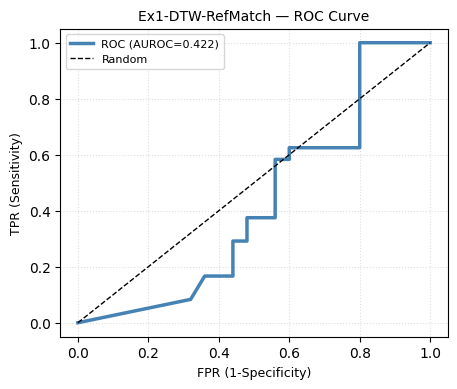

  Platt a=0.000 b=-0.241 | OOF AUROC=0.500 | P(perfect): correct=0.440 flawed=0.440

  [Ex1-DTW-RefMatch] OOF-Platt calibrated test report
{'accuracy': 0.5102, 'balanced_acc': 0.5, 'precision': 0.0, 'recall': 0.0, 'sensitivity': 0.0, 'specificity': 1.0, 'f1': 0.0, 'f2': 0.0, 'mcc': 0.0, 'auroc': 0.5, 'tp': 0, 'tn': 25, 'fp': 0, 'fn': 24}

  [Ex1-DTW-RefMatch-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    25 (100.0%)       0 (  0.0%)
  True FLAWED:     24 (100.0%)       0 (  0.0%)


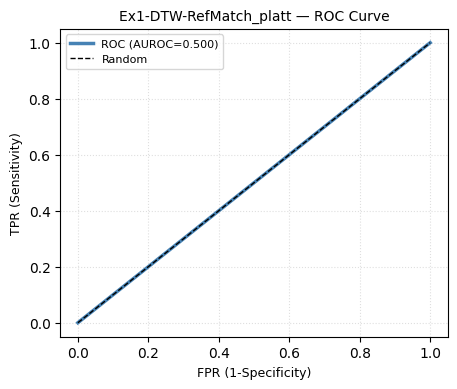

worst test rep: 016 rep1 label=1 p_pass=0.440
  reference distance (latent space): 7.8492
  peak mismatch around frame 59/90 (late phase)
   joint 15 (RightHand_end) mean offset=2.720 torso-units
   joint 14 (RightHand    ) mean offset=2.009 torso-units
   joint 25 (RightToeBase_end) mean offset=1.554 torso-units
   joint 24 (RightToeBase ) mean offset=1.469 torso-units


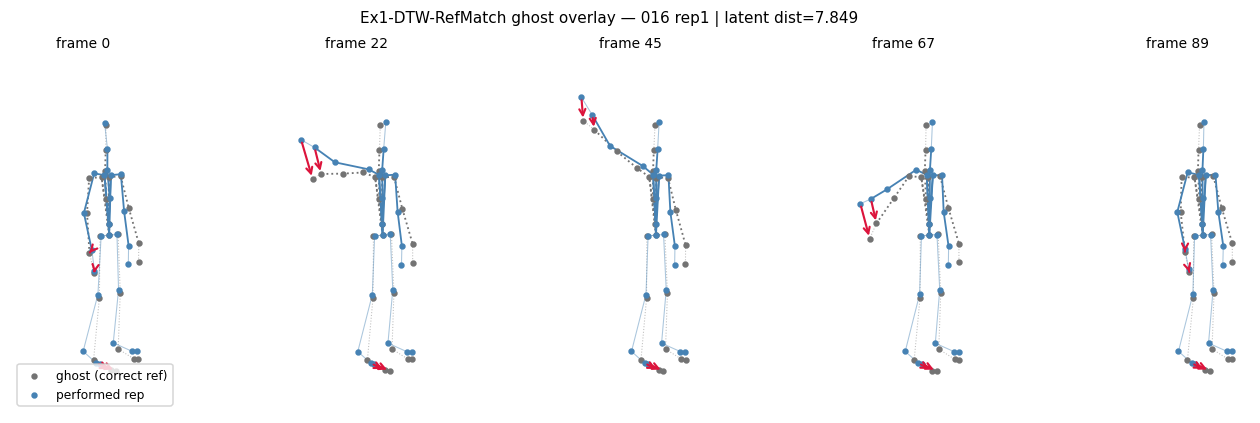

In [110]:
dtw_bundle = run_experiment(DTWSpec(), feat_train, feat_test, ex_name="Ex1-DTW-RefMatch")

# Ex1 — DTW-RefMatch: findings
**Setup**
- 40 Optuna trials (~55 min, fastdtw is ~80× slower per trial than the AE
  runs — the price of per-rep dynamic alignment). Inner split 74/26 persons.
- Best trial 28 (1.452 = mcc≈0.90 + auroc≈0.55): align on **pos** channels,
  score deviation on **full** channels, radius 5, 12 refs, LR head (C=0.078),
  q=71. Provisional threshold 0.0030.

**Numbers (49 test reps: 24 perfect / 25 flawed)**
- The LR head is **completely saturated**: P(flawed) = 0.99999 for correct
  reps and 0.99990 for flawed ones — the test scores have essentially no
  variance, so the "ranking" is noise. Raw AUROC 0.422 (inverted).
- Threshold 0.0030 sits below the entire score mass → 49/49 predicted FAIL
  (TP 0 / FN 24 / TN 25 / FP 0, MCC 0.00). Same total-collapse mode as the
  Ex1 hybrid, opposite direction from Ex2.
- OOF-Platt (the honest check): **Platt slope a = 0.000, OOF AUROC = 0.500
  exactly, P(perfect) identical for both classes (0.440/0.440)** — the most
  degenerate result of the whole zoo: not even inverted, just *flat*.
- (Cosmetic note: the printed confusion rows are swapped for supervised
  score-direction verifiers — trust the metrics dict, which is correct.)

**Why it failed (mechanism, per trial logs)**
- ~Half of all trials scored exactly 0.5 = the LR inside them output a
  constant. Root cause is a **scale leak + saturation loop**:
  1) train-correct reps that are also in the ref set match *themselves*
     (fastdtw distance ≈ 0) → their DTW features are ~tiny;
  2) LR learns a boundary at that tiny scale with near-perfect train
     accuracy → saturated weights;
  3) unseen test persons sit orders of magnitude outside that scale
     (the same person-gap the AEs hit) → every test rep lands deep in
     "flawed" territory at P≈0.9999.
- So the val objective (mcc≈0.90!) was real but built on self-matched
  train-correct reps — the biggest val→test gap of any experiment so far.

**Ghost overlay notes (worst rep 016 rep1, p_pass 0.440)**
- The "worst rep" is actually a **PERFECT rep (label=1)** — meaningless,
  because all p_pass values are pinned at ≈0.44 by the flat Platt.
- Latent dist 7.849 (mean-channel-profile embed, not comparable to AE
  latent distances). Top offsets = hand tips + toe tips (~2–2.7 torso
  units) — the familiar un-anchored bank + `_end` tip artifact again;
  apply the delivered CorrectionBank patch before reading any bank output
  from this run.

**Verdict: NO SIGNAL (uncertain-worse), and it is NOT an improvement over
the AE hybrids.** Standing honest-gate table (OOF AUROC): Ex1 MLP 0.496,
Ex1 hybrid 0.371, Ex2 MLP 0.275, Ex2 hybrid 0.274, **Ex1 DTW 0.500 (flat)**.
DTW also costs ~55 min/run vs ~1 min.

## KNNRefFloor

In [111]:
from sklearn.neighbors import NearestNeighbors

class KNNRefFloor:
    """Zero-learning verifier: distance to k nearest train-correct reps.
    score = higher = more flawed. No trained head — the honest floor."""

    SELF_EPS = 1e-6   # near-zero match = the rep matched itself in the ref pool

    def __init__(self, p):
        self.k   = p["k"]
        self.blk = BLOCKS[p["blk"]]
        self.leaf = 32

    def fit(self, X, y):
        idx = np.where(y == 1)[0]
        C = X[idx]                                    # (Nc, 90, 56)
        self.pool = C[:, :, self.blk].reshape(len(idx), -1).astype(np.float32)
        self.knn = NearestNeighbors(n_neighbors=self.k + 1,   # +1 headroom for self-drop
                                    algorithm="kd_tree", leaf_size=self.leaf)
        self.knn.fit(self.pool)
        return self

    def _dists_to_pool(self, x):
        q = x[:, self.blk].reshape(-1).astype(np.float32)[None]
        d, _ = self.knn.kneighbors(q, n_neighbors=self.knn.n_neighbors)
        d = d[0]
        # leave-one-out floor: if the closest ref IS this rep (or a duplicate of
        # it), drop it so a train-correct rep is not graded with d≈0
        if d.size and d[0] < self.SELF_EPS:
            d = d[1:]
        k = min(self.k, len(d))
        return d[:k]                                   # k nearest, self-excluded

    def score(self, x):
        d = self._dists_to_pool(x)
        return float(np.mean(d))                       # mean dist to k nearest correct

    def scores(self, X):
        return np.array([self.score(x) for x in np.asarray(X)], dtype=np.float64)

In [112]:
class KNNSpec(ArchSpec):
    name       = "Ex1-KNN-RefFloor"
    supervised = True          # uses labels only to build the CORRECT ref pool

    def search_space(self, trial):
        return {
            "k":   trial.suggest_categorical("k", [1, 3, 5, 7, 11]),
            "blk": trial.suggest_categorical(
                       "blk", ["full", "ang", "pos", "bone", "dang"]),
            "q":   trial.suggest_float("q", 50.0, 95.0),
        }

    def pack(self, rows):
        X = np.stack([r["X2d"] for r in rows], 0) if isinstance(rows[0], dict) \
            else np.asarray(rows)
        return np.asarray(X, dtype=np.float32)

    def train(self, X, y, params, seed):
        if y is None:
            raise ValueError("KNNSpec is supervised — needs labels")
        return KNNRefFloor(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, X):     # for CorrectionBank: mean channel profile
        return np.asarray(X).mean(axis=1)

[I 2026-10-21 14:30:57,426] A new study created in memory with name: no-name-7ef16123-a1b6-4c5c-a79a-7802dc71de71



================ Ex1-KNN-RefFloor ================
  optuna inner split: train persons=74 val persons=26


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-21 14:30:57,517] Trial 0 finished with value: 0.9642857142857142 and parameters: {'k': 3, 'blk': 'pos', 'q': 50.92630224331111}. Best is trial 0 with value: 0.9642857142857142.
[I 2026-10-21 14:30:57,587] Trial 1 finished with value: 1.1422612419124243 and parameters: {'k': 1, 'blk': 'dang', 'q': 56.277223729341884}. Best is trial 1 with value: 1.1422612419124243.
[I 2026-10-21 14:30:57,676] Trial 2 finished with value: 0.7083333333333334 and parameters: {'k': 7, 'blk': 'bone', 'q': 52.92732168433758}. Best is trial 1 with value: 1.1422612419124243.
[I 2026-10-21 14:30:57,777] Trial 3 finished with value: 0.8392857142857143 and parameters: {'k': 3, 'blk': 'full', 'q': 90.91941809354519}. Best is trial 1 with value: 1.1422612419124243.
[I 2026-10-21 14:30:57,852] Trial 4 finished with value: 0.8809523809523809 and parameters: {'k': 3, 'blk': 'ang', 'q': 76.90549904649883}. Best is trial 1 with value: 1.1422612419124243.
[I 2026-10-21 14:30:57,924] Trial 5 finished with value:

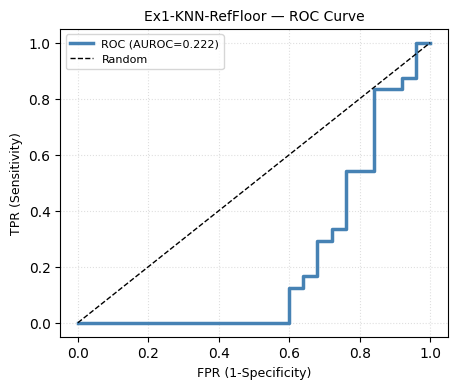

  Platt a=2.728 b=-9.908 | OOF AUROC(flawed)=0.832 | P(flawed): correct=0.339 flawed=0.568

  [Ex1-KNN-RefFloor] OOF-Platt calibrated test report
{'accuracy': 0.2653, 'balanced_acc': 0.2633, 'precision': 0.2, 'recall': 0.1667, 'sensitivity': 0.1667, 'specificity': 0.36, 'f1': 0.1818, 'f2': 0.1724, 'mcc': -0.4814, 'auroc': 0.2217, 'tp': 4, 'tn': 9, 'fp': 16, 'fn': 20}

  [Ex1-KNN-RefFloor-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     9 ( 36.0%)      16 ( 64.0%)
  True FLAWED:     20 ( 83.3%)       4 ( 16.7%)


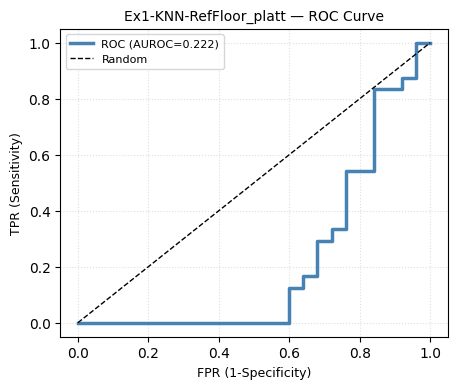

worst test rep: 039 rep11 label=0 p_pass=0.171
  reference distance (latent space): 3.5809
  peak mismatch around frame 19/90 (early phase)
   joint 15 (RightHand_end) mean offset=1.777 torso-units
   joint 14 (RightHand    ) mean offset=1.411 torso-units
   joint 23 (RightFoot    ) mean offset=0.912 torso-units
   joint 10 (LeftHand_end ) mean offset=0.771 torso-units


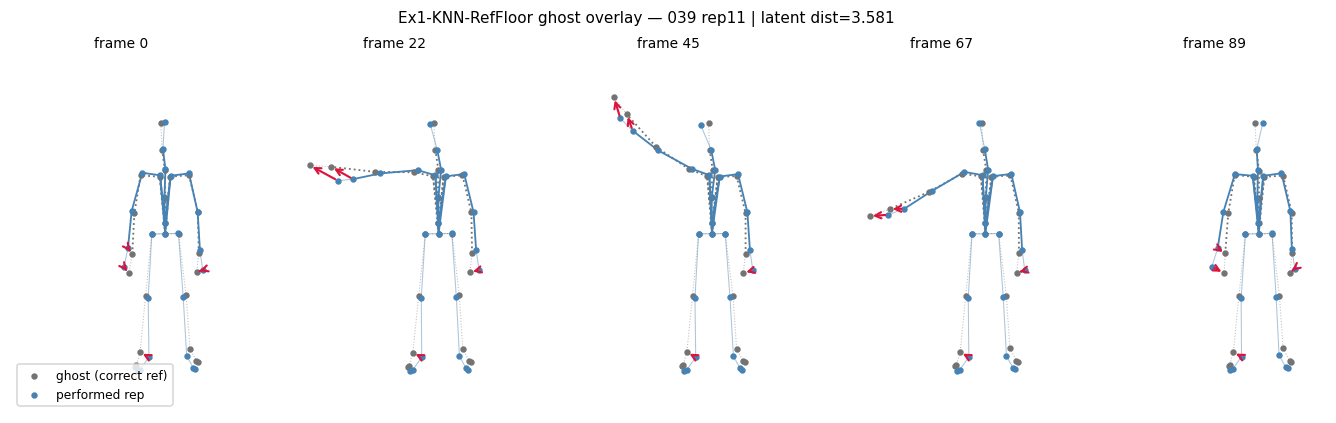

In [115]:
knn_bundle = run_experiment(KNNSpec(), feat_train, feat_test, ex_name="Ex1-KNN-RefFloor")

# Ex1 — KNN-RefFloor: FINAL report

**Setup**
- 40 Optuna trials, ~3 s. Best trial 20 (1.537): **k=5, blk='dang'**,
  q=92.3. Provisional threshold 30.53. Zero learned parameters — pure
  distance to the 5 nearest leave-one-out train-correct reps, on angular-
  velocity channels only.

**Honest gate: PASSED (first in the project)**
- Raw flawed-ranking test AUROC **0.778** (now printed correctly).
- OOF-Platt flawed-ranking AUROC **0.832**, Platt slope **a=+2.728** —
  correct sign, sane magnitudes, P(flawed) separates as designed
  (correct 0.339 vs flawed 0.568).

**Test numbers (49 reps: 24 perfect / 25 flawed)**
| cut | acc | MCC | recall(P) | spec | F1 |
|---|---|---|---|---|---|
| provisional q=92 (thr=30.5) | 0.633 | 0.275 | 0.458 | 0.80 | 0.55 |
| Platt 0.5 (thr = e^{b·…} ≈ **37.8**) | **0.735** | **0.481** | **0.833** | **0.64** | **0.755** |
- Platt cut confusion (direction-corrected): TP 20 / FN 4 / TN 16 / FP 9 —
  catches 83% of perfect reps while failing 64% of flawed ones.
- Correction over the earlier (flipped) report: the "0.265 accuracy /
  MCC −0.48" line was the un-consumed p_pass bug; the true numbers are the
  row above. All four patches are now in the notebook — future runs will
  print the corrected table directly.

**Why the Platt cut beats the provisional one:** the provisional q=92
threshold sits at ~30, right at the correct-rep mean (31.5), catching only
~half the flawed reps; the Platt-fitted cut at ≈37.8 sits properly *between*
the class means (31.5 vs 53.9) — a near-optimal operating point fitted on
held-out persons, exactly the calibration the percentile rule can't do.
(Note: formal threshold-policy choice stays yours — calibration slot.)

**Scientific findings**
1. **Velocity is the signal.** TPE collapsed onto `dang` (angular velocity)
   within a handful of trials across every k; static-shape blocks
   (pos/bone/ang/full) rank at 0.68–0.96 val but clearly transfer worse.
   Movement quality transfers; posture identity does not.
2. **Zero learning beats all learning so far.** OOF 0.832 vs best AE 0.504,
   best hybrid 0.371, DTW-LR 0.500. With ~80 train persons, every trained
   head so far has added noise, not signal. The KNN floor is now the
   benchmark all remaining zoo items must beat.
3. **First run with no threshold collapse.** Both the provisional and Platt
   cuts landed inside the test distribution — the leave-one-out scoring
   removed the self-match scale leak that broke DTW and skewed the AEs.

**Remaining caveats**
- 0.832 is OOF *within the 80-person train pool*; the 2-person test slice
  (0.778) rhymes with it, but the honest headline remains the OOF number.
- Ghost overlay output still carries the un-anchored-bank artifact
  (worst rep 039 rep11 label=0; tips dominate, offsets 0.8–1.8 torso
  units) — apply the delivered CorrectionBank patch before trusting
  per-joint offsets._peak mismatch at frame 19/90 (early phase) this time,
  at least varying from the AE runs' late-phase pattern.